## Import Packages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly

from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics import (
    roc_auc_score, recall_score, accuracy_score, f1_score, precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

print("All core packages imported successfully.")
warnings.filterwarnings("ignore")   

All core packages imported successfully.


In [2]:
from sklearn import set_config

from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

import optuna
from lightgbm import LGBMClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

print("LightGBM, Optuna, imbalanced-learn imported successfully.")

LightGBM, Optuna, imbalanced-learn imported successfully.


In [3]:
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
import dagshub
import mlflow

DAGSHUB_USER_TOKEN = os.getenv("DAGSHUB_USER_TOKEN")

dagshub.init(repo_owner='Ankitkumar1141', repo_name='Churn-modelling', mlflow=True)
mlflow.set_tracking_uri('https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow')
mlflow.set_experiment('Experiment 7 - LGBM HP Tuning')
print('MLflow tracking active on DagsHub.')

Accessing as Ankitkumar1141

Initialized MLflow to track repo "Ankitkumar1141/Churn-modelling"

Repository Ankitkumar1141/Churn-modelling initialized!

2026/11/11 19:43:13 INFO mlflow.tracking.fluent: Experiment with name 'Experiment 7 - LGBM HP Tuning' does not exist. Creating a new experiment.


MLflow tracking active on DagsHub.


In [5]:
try:
    mlflow.set_tracking_uri("https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow")
    mlflow.set_experiment("Experiment 7 - LGBM HP Tuning")
    print("MLflow tracking active on DagsHub.")
except Exception as e:
    print(f"[MLflow Notice] {e}")

MLflow tracking active on DagsHub.


In [6]:
df = pd.read_csv("preprocessed.csv")
print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (10000, 37)


,customer_id,name,gender,age,salary,location_id,churned,account_id,tenure,balance,...,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female,geo_france,geo_germany,geo_spain,geo_uk,geo_usa
0,15634602,Hargrave,female,42,101348.88,2,1,A15634602SID,2,NaN,...,1,0,0.750000,0,1,1,0,0,0,0
1,15647311,Hill,female,41,112542.58,6,0,A15647311SID,1,83807.86,...,1,0,0.416667,0,1,0,0,0,0,1
2,15619304,Onio,female,42,113931.57,4,1,A15619304SID,8,159660.80,...,0,0,0.583333,0,1,0,0,0,1,0


## Exploratory Checks

In [7]:
df.dtypes

customer_id                  int64
name                        object
gender                      object
age                          int64
salary                     float64
location_id                  int64
churned                      int64
account_id                  object
tenure                       int64
balance                    float64
num_products                 int64
has_credit_card              int64
is_active                    int64
geography                   object
age_group                   object
salary_bracket              object
tenure_group                object
has_balance                  int64
churn_label                 object
has_credit_card_label       object
is_active_label             object
balance_to_salary          float64
balance_per_product        float64
age_when_joined              int64
products_per_tenure        float64
is_senior_risk               int64
is_extreme_product_risk      int64
is_single_product            int64
inactive_senior     

In [8]:
df.isna().sum().sort_values(ascending=False).head(5)

balance        3617
name              0
gender            0
age               0
customer_id       0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
print(df["churned"].value_counts())
churn_rate = df["churned"].mean()
print("\nChurn rate: {:.2%}".format(churn_rate))

churned
0    7963
1    2037
Name: count, dtype: int64

Churn rate: 20.37%


## Drop Unnecessary Columns

In [11]:
# Drop columns identified in prior notebooks as non-predictive or redundant.
# This matches the drop list in model_selection.ipynb and XGB_HP_Tuning.ipynb exactly.
drop_columns = [
    "has_balance",
    "products_per_tenure",
    "has_credit_card",
    "geo_france", "geo_uk", "geo_usa", "geo_spain", "geo_germany",
    "tenure", "salary",
    "customer_id",
    "account_id", "name", "location_id",
    "age_when_joined", "age",
    "churn_label",
    "has_credit_card_label",
    "is_active_label",
]

df = df.drop(columns=drop_columns)
print("Shape after dropping columns:", df.shape)
df.head(3)

Shape after dropping columns: (10000, 18)


,gender,churned,balance,num_products,is_active,geography,age_group,salary_bracket,tenure_group,balance_to_salary,balance_per_product,is_senior_risk,is_extreme_product_risk,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female
0,female,1,NaN,1,1,france,36-45,high,new (0-2),0.000000,0.000000,0,0,1,0,0.750000,0,1
1,female,0,83807.86,1,1,usa,36-45,high,new (0-2),0.744670,83807.860000,0,0,1,0,0.416667,0,1
2,female,1,159660.80,3,0,uk,36-45,high,veteran (8-10),1.401362,53220.266667,0,1,0,0,0.583333,0,1


In [12]:
missing_cols = df.isna().any(axis=0).loc[lambda x: x].index.tolist()
print("Columns with missing values:", missing_cols)

Columns with missing values: ['balance']


In [13]:
pct_missing_rows = df.isna().any(axis=1).mean().round(4) * 100
n_missing = df.isna().any(axis=1).sum()
print(f"Rows with missing values: {pct_missing_rows:.2f}%  ({n_missing:,} rows)")

Rows with missing values: 36.17%  (3,617 rows)


## Train / Test Split

In [14]:
X = df.drop(columns="churned")
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Train size : {:,}  |  churn rate: {:.2%}".format(X_train.shape[0], y_train.mean()))
print("Test  size : {:,}  |  churn rate: {:.2%}".format(X_test.shape[0], y_test.mean()))

Train size : 8,000  |  churn rate: 20.38%
Test  size : 2,000  |  churn rate: 20.35%


In [15]:
print("Train shape:", X_train.shape)
print("Test  shape:", X_test.shape)
missing_in_train = X_train.isna().sum()
print("Missing in train (balance only):\n", missing_in_train[missing_in_train > 0])

Train shape: (8000, 17)
Test  shape: (2000, 17)
Missing in train (balance only):
 balance    2891
dtype: int64


## Column Type Identification

In [16]:
numeric_cols     = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
binary_cols      = [c for c in numeric_cols if X[c].nunique() == 2]
scale_cols       = [c for c in numeric_cols if c not in binary_cols]

print("Numeric (to scale) :", scale_cols)
print("Binary pass-thru   :", binary_cols)
print("Categorical OHE    :", categorical_cols)

Numeric (to scale) : ['balance', 'num_products', 'balance_to_salary', 'balance_per_product', 'engagement_score']
Binary pass-thru   : ['is_active', 'is_senior_risk', 'is_extreme_product_risk', 'is_single_product', 'inactive_senior', 'high_risk_inactive', 'is_female']
Categorical OHE    : ['gender', 'geography', 'age_group', 'salary_bracket', 'tenure_group']


## Preprocessing Pipeline

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scale",          MinMaxScaler(), scale_cols),
        ("nominal_encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_cols),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

knn_imputer = KNNImputer(n_neighbors=10)

In [18]:
# Fit preprocessor + KNN imputer on training data only; transform both splits
base_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  knn_imputer),
])

X_train_trans = base_pipeline.fit_transform(X_train)
X_test_trans  = base_pipeline.transform(X_test)

print("X_train transformed shape:", X_train_trans.shape)
print("X_test  transformed shape:", X_test_trans.shape)

X_train transformed shape: (8000, 28)
X_test  transformed shape: (2000, 28)


In [19]:
sampler = RandomUnderSampler(random_state=42)

# Apply resampling to training data only (never to test set)
X_train_resampled, y_train_resampled = sampler.fit_resample(X_train_trans, y_train)

In [20]:
print("Before resampling — Train shape:", X_train_trans.shape)
print("Before resampling — Class distribution:")
print(y_train.value_counts())
print()
print("After  resampling — Train shape:", X_train_resampled.shape)
print("After  resampling — Class distribution:")
print(y_train_resampled.value_counts())

Before resampling — Train shape: (8000, 28)
Before resampling — Class distribution:
churned
0    6370
1    1630
Name: count, dtype: int64

After  resampling — Train shape: (3260, 28)
After  resampling — Class distribution:
churned
0    1630
1    1630
Name: count, dtype: int64



| Hyperparameter | Search Space | Description |
|---|---|---|
| `n_estimators` | 50 – 800 | Number of boosting rounds |
| `max_depth` | 2 – 20 | Max tree depth — controls model complexity |
| `learning_rate` | 0.005 – 0.3 | Step-size shrinkage (η) — log scale |
| `num_leaves` | 15 – 200 | Max leaves per tree — LGBM's primary complexity control |
| `subsample` | 0.5 – 1.0 | Row-sampling fraction per iteration |
| `colsample_bytree` | 0.5 – 1.0 | Feature-sampling fraction per tree |
| `min_child_samples` | 5 – 100 | Min data per leaf — primary regularisation |
| `reg_alpha` | 1e-8 – 10.0 | L1 regularisation — log scale |
| `reg_lambda` | 1e-8 – 10.0 | L2 regularisation — log scale |

> **Note:** `class_weight` is NOT needed — Random UnderSampling already balances the training set.

In [21]:
def objective(trial):
    with mlflow.start_run(nested=True):
        params = {
            "n_estimators"     : trial.suggest_int("n_estimators", 50, 800),
            "max_depth"        : trial.suggest_int("max_depth", 2, 20),
            "learning_rate"    : trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
            "num_leaves"       : trial.suggest_int("num_leaves", 15, 200),
            "subsample"        : trial.suggest_float("subsample", 0.5, 1.0),
            "colsample_bytree" : trial.suggest_float("colsample_bytree", 0.5, 1.0),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
            "reg_alpha"        : trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda"       : trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
            "random_state"     : 42,
            "n_jobs"           : -1,
            "verbosity"        : -1,
        }

        # log all hyperparameters
        mlflow.log_params(params)

        # build the model
        lgbm = LGBMClassifier(**params)

        # 5-fold stratified cross-validation on resampled training data
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

        cv_scores = cross_validate(
            lgbm,
            X_train_resampled,
            y_train_resampled,
            cv=cv,
            scoring={
                "roc_auc" : "roc_auc",
                "recall"  : "recall",
                "f1"      : "f1",
            },
            n_jobs=-1,
        )

        mean_roc_auc = cv_scores["test_roc_auc"].mean()
        mean_recall  = cv_scores["test_recall"].mean()
        mean_f1      = cv_scores["test_f1"].mean()

        # log CV metrics
        mlflow.log_metric("cv_mean_roc_auc", mean_roc_auc)
        mlflow.log_metric("cv_mean_recall",  mean_recall)
        mlflow.log_metric("cv_mean_f1",      mean_f1)

        return mean_roc_auc

In [22]:
# create Optuna study — maximise ROC-AUC
study = optuna.create_study(direction="maximize", study_name="lgbm_hp_tuning")

with mlflow.start_run(run_name="LGBM HP Tuning — Best Model") as parent:
    # optimize the objective function
    study.optimize(objective, n_trials=50, n_jobs=-1, show_progress_bar=True)

    # log the best parameters
    mlflow.log_params(study.best_params)

    # log the best score
    mlflow.log_metric("best_cv_roc_auc", study.best_value)

  0%|          | 0/50 [00:00<?, ?it/s]

🏃 View run sincere-auk-664 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6/runs/81cad9533e8040bf9d9d954feb1a8bd3
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6


Best trial: 5. Best value: 0.82551:   2%|▏         | 1/50 [00:31<25:27, 31.17s/it]

🏃 View run gifted-cod-983 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6/runs/12fdbd90cc90405eb67d348a2614e02a
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6


Best trial: 9. Best value: 0.841263:   4%|▍         | 2/50 [00:32<10:53, 13.61s/it]

🏃 View run dashing-sow-907 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6/runs/63962fbd36c545959e402158939c4c65
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6
🏃 View run smiling-stork-935 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6/runs/88001045c6ed44f39511e7190044bba2
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6


... (48 outputs left out)

Best trial: 39. Best value: 0.845227:  94%|█████████▍| 47/50 [09:26<00:31, 10.66s/it]

🏃 View run agreeable-colt-436 at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6/runs/c9a0481467134a4586ad838ef28cb2e2
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6


Best trial: 39. Best value: 0.845227: 100%|██████████| 50/50 [09:41<00:00, 11.64s/it]


🏃 View run LGBM HP Tuning — Best Model at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6/runs/b6601f252ade48c289205a5ed1e62076
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6


In [23]:
# best CV ROC-AUC achieved across all 50 trials
print("Best CV ROC-AUC :", round(study.best_value, 4))

Best CV ROC-AUC : 0.8452


In [24]:
# best hyperparameters found by Optuna
print("Best Parameters:")
for k, v in study.best_params.items():
    print(f"  {k:22s}: {v}")

Best Parameters:
  n_estimators          : 170
  max_depth             : 4
  learning_rate         : 0.013696776782276106
  num_leaves            : 93
  subsample             : 0.6706077847465436
  colsample_bytree      : 0.7788606853399158
  min_child_samples     : 45
  reg_alpha             : 0.0010091362976158678
  reg_lambda            : 1.4687186523366987e-06


In [25]:
# full trials dataframe sorted by objective value
study.trials_dataframe().sort_values("value", ascending=False)

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_alpha,params_reg_lambda,params_subsample,state
39,39,0.845227,2026-11-11 19:48:55.695416,2026-11-11 19:51:00.147036,0 days 00:02:04.451620,0.778861,0.013697,4,45,170,93,1.009136e-03,1.468719e-06,0.670608,COMPLETE
37,37,0.844568,2026-11-11 19:48:26.961195,2026-11-11 19:51:07.838175,0 days 00:02:40.876980,0.777728,0.013100,4,5,170,194,1.089580e-03,9.014808e-07,0.670718,COMPLETE
32,32,0.844547,2026-11-11 19:47:54.952747,2026-11-11 19:50:51.710524,0 days 00:02:56.757777,0.829254,0.009954,4,8,200,89,3.150086e-01,7.619468e-07,0.548426,COMPLETE
27,27,0.844361,2026-11-11 19:46:59.647212,2026-11-11 19:48:55.688008,0 days 00:01:56.040796,0.865943,0.008123,5,29,237,102,3.871050e-02,1.232900e-05,0.596366,COMPLETE
29,29,0.844291,2026-11-11 19:47:35.021420,2026-11-11 19:49:34.952499,0 days 00:01:59.931079,0.875580,0.009222,5,6,181,182,4.897178e-01,1.146945e-06,0.555845,COMPLETE
26,26,0.844134,2026-11-11 19:46:07.508228,2026-11-11 19:48:26.954217,0 days 00:02:19.445989,0.875809,0.007119,5,26,292,100,3.554216e-02,2.413759e-05,0.611954,COMPLETE
22,22,0.844048,2026-11-11 19:45:38.906417,2026-11-11 19:48:11.044220,0 days 00:02:32.137803,0.840521,0.005711,5,27,240,111,2.244124e-02,3.572950e-05,0.604521,COMPLETE
31,31,0.843858,2026-11-11 19:47:51.227480,2026-11-11 19:50:03.243418,0 days 00:02:12.015938,0.846804,0.009635,4,5,193,97,2.432215e-01,1.041968e-06,0.567259,COMPLETE
6,6,0.843692,2026-11-11 19:43:22.202126,2026-11-11 19:45:03.506760,0 days 00:01:41.304634,0.857325,0.224184,2,11,794,64,8.890818e+00,2.415083e-04,0.547881,COMPLETE
23,23,0.843608,2026-11-11 19:45:46.830102,2026-11-11 19:48:15.892686,0 days 00:02:29.062584,0.857834,0.005645,5,25,236,114,1.629330e-02,2.463967e-05,0.596219,COMPLETE


## Optuna Visualisations

In [26]:
# optimization history plot
optuna.visualization.plot_optimization_history(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'mode': 'markers',
              'name': 'Objective Value',
              'type': 'scatter',
              'x': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17,
                    18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
                    34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
              'y': [0.8351019985697619, 0.8372605291881516, 0.7932901125371675,
                    0.8392515713801798, 0.8284664458579547, 0.8255099928488088,
                    0.8436918965711921, 0.8123612104332116, 0.8040545372426511,
                    0.8412633143889495, 0.8067174150325567, 0.8419586736422147,
                    0.8394839850954119, 0.8289858481689187, 0.7985537656667544,
                    0.8164957281041815, 0.8421741503255673, 0.8424526704053596,
                    0.8425778162520231, 0.8388958937107155, 0.8415192517595693,
                    0.8409208099665022, 0.8440475742406564, 0.843608152358011,
                    0.843223305355866, 0.8431724942602281, 0.8441341412924837,
                    0.8443609093304227, 0.8426784974970831, 0.8442912793104747,
                    0.8430247657043923, 0.8438584440513379, 0.8445472166810944,
                    0.8342843163084798, 0.8406018291994428, 0.8352073845458993,
                    0.8430831043697543, 0.8445679174978358, 0.8334252324137152,
                    0.8452265798486959, 0.8415550077157589, 0.8419125672776543,
                    0.8409368060521661, 0.8422268433136362, 0.8398396627648763,
                    0.8378966088298393, 0.8410817117693552, 0.8418297640106891,
                    0.8420348902856712, 0.8423905679551357]},
             {'mode': 'lines',
              'name': 'Best Value',
              'type': 'scatter',
              'x': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17,
                    18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
                    34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
              'y': [0.8351019985697619, 0.8372605291881516, 0.8372605291881516,
                    0.8392515713801798, 0.8392515713801798, 0.8392515713801798,
                    0.8436918965711921, 0.8436918965711921, 0.8436918965711921,
                    0.8436918965711921, 0.8436918965711921, 0.8436918965711921,
                    0.8436918965711921, 0.8436918965711921, 0.8436918965711921,
                    0.8436918965711921, 0.8436918965711921, 0.8436918965711921,
                    0.8436918965711921, 0.8436918965711921, 0.8436918965711921,
                    0.8436918965711921, 0.8440475742406564, 0.8440475742406564,
                    0.8440475742406564, 0.8440475742406564, 0.8441341412924837,
                    0.8443609093304227, 0.8443609093304227, 0.8443609093304227,
                    0.8443609093304227, 0.8443609093304227, 0.8445472166810944,
                    0.8445472166810944, 0.8445472166810944, 0.8445472166810944,
                    0.8445472166810944, 0.8445679174978358, 0.8445679174978358,
                    0.8452265798486959, 0.8452265798486959, 0.8452265798486959,
                    0.8452265798486959, 0.8452265798486959, 0.8452265798486959,
                    0.8452265798486959, 0.8452265798486959, 0.8452265798486959,
                    0.8452265798486959, 0.8452265798486959]},
             {'marker': {'color': '#cccccc'},
              'mode': 'markers',
              'name': 'Infeasible Trial',
              'showlegend': False,
              'type': 'scatter',
              'x': [],
              'y': []}],
    'layout': {'template': '...',
               'title': {'text': 'Optimization History Plot'},
               'xaxis': {'title': {'text': 'Trial'}},
               'yaxis': {'title': {'text': 'Objective Value'}}}
})

In [27]:
# hyperparameter importance plot
optuna.visualization.plot_param_importances(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'cliponaxis': False,
              'hovertemplate': [reg_lambda (FloatDistribution):
                                0.0017790241670900503<extra></extra>, subsample
                                (FloatDistribution):
                                0.05612447246437326<extra></extra>, num_leaves
                                (IntDistribution):
                                0.05719191241285865<extra></extra>, reg_alpha
                                (FloatDistribution):
                                0.06376864233075087<extra></extra>, n_estimators
                                (IntDistribution):
                                0.11016564788632006<extra></extra>,
                                min_child_samples (IntDistribution):
                                0.11265697730863218<extra></extra>, max_depth
                                (IntDistribution):
                                0.17332490228524866<extra></extra>,
                                colsample_bytree (FloatDistribution):
                                0.18639363726704658<extra></extra>, learning_rate
                                (FloatDistribution):
                                0.23859478387767974<extra></extra>],
              'name': 'Objective Value',
              'orientation': 'h',
              'text': [<0.01, 0.06, 0.06, 0.06, 0.11, 0.11, 0.17, 0.19, 0.24],
              'textposition': 'outside',
              'type': 'bar',
              'x': [0.0017790241670900503, 0.05612447246437326,
                    0.05719191241285865, 0.06376864233075087, 0.11016564788632006,
                    0.11265697730863218, 0.17332490228524866, 0.18639363726704658,
                    0.23859478387767974],
              'y': [reg_lambda, subsample, num_leaves, reg_alpha, n_estimators,
                    min_child_samples, max_depth, colsample_bytree, learning_rate]}],
    'layout': {'template': '...',
               'title': {'text': 'Hyperparameter Importances'},
               'xaxis': {'title': {'text': 'Hyperparameter Importance'}},
               'yaxis': {'title': {'text': 'Hyperparameter'}}}
})

In [28]:
# slice plot -- individual parameter effect on objective
optuna.visualization.plot_slice(study)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'marker': {'color': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,
                                   14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25,
                                   26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37,
                                   38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
                         'colorbar': {'title': {'text': 'Trial'}, 'x': 1.0, 'xpad': 40},
                         'colorscale': [[0.0, 'rgb(247,251,255)'], [0.125,
                                        'rgb(222,235,247)'], [0.25,
                                        'rgb(198,219,239)'], [0.375,
                                        'rgb(158,202,225)'], [0.5,
                                        'rgb(107,174,214)'], [0.625,
                                        'rgb(66,146,198)'], [0.75,
                                        'rgb(33,113,181)'], [0.875,
                                        'rgb(8,81,156)'], [1.0, 'rgb(8,48,107)']],
                         'line': {'color': 'Grey', 'width': 0.5},
                         'showscale': True},
              'mode': 'markers',
              'name': 'Feasible Trial',
              'showlegend': False,
              'type': 'scatter',
              'x': [0.9472005906696388, 0.7016406627691483, 0.6251664611192631,
                    0.5735186804878655, 0.6054220407985214, 0.5734356337235651,
                    0.8573248853526858, 0.9895033078255573, 0.5238405768336005,
                    0.550314596894626, 0.5234295630204757, 0.8358398709371476,
                    0.7343979679464692, 0.9786137484590829, 0.5886973926823235,
                    0.7623345293304675, 0.9973153047192473, 0.9037553605012663,
                    0.8639883107456559, 0.9767224139997783, 0.9098217545109496,
                    0.8432859326625631, 0.8405209227031747, 0.8578344017648968,
                    0.8619960393321195, 0.8535108843902879, 0.8758088742994722,
                    0.8659433999519276, 0.8917073902347004, 0.8755796684593398,
                    0.8688962442904297, 0.8468036263491048, 0.8292537946899826,
                    0.7896124890812957, 0.798086368825161, 0.81293959748844,
                    0.8070198639349151, 0.7777277073909772, 0.7878287579779305,
                    0.7788606853399158, 0.7963564716397266, 0.7995106386367891,
                    0.7993592611290615, 0.7764539583365317, 0.9369656003241973,
                    0.669852237788794, 0.6512726876439003, 0.6802266396640955,
                    0.6974623743858511, 0.6463370237861275],
              'xaxis': 'x',
              'y': [0.8351019985697619, 0.8372605291881516, 0.7932901125371675,
                    0.8392515713801798, 0.8284664458579547, 0.8255099928488088,
                    0.8436918965711921, 0.8123612104332116, 0.8040545372426511,
                    0.8412633143889495, 0.8067174150325567, 0.8419586736422147,
                    0.8394839850954119, 0.8289858481689187, 0.7985537656667544,
                    0.8164957281041815, 0.8421741503255673, 0.8424526704053596,
                    0.8425778162520231, 0.8388958937107155, 0.8415192517595693,
                    0.8409208099665022, 0.8440475742406564, 0.843608152358011,
                    0.843223305355866, 0.8431724942602281, 0.8441341412924837,
                    0.8443609093304227, 0.8426784974970831, 0.8442912793104747,
                    0.8430247657043923, 0.8438584440513379, 0.8445472166810944,
                    0.8342843163084798, 0.8406018291994428, 0.8352073845458993,
                    0.8430831043697543, 0.8445679174978358, 0.8334252324137152,
                    0.8452265798486959, 0.8415550077157589, 0.8419125672776543,
                    0.8409368060521661, 0.8422268433136362, 0.8398396627648763,
                    0.8378966088298393, 0.8410817117693552, 0.8418297640106891,
                    0.8420348902856712, 0.8423905679551357],
              'yaxis': 'y'},
             {'marker

In [29]:
# parallel coordinate plot -- interactions between key LGBM params
optuna.visualization.plot_parallel_coordinate(
    study,
    params=["n_estimators", "max_depth", "learning_rate", "num_leaves", "subsample"]
)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'dimensions': [{'label': 'Objective Value',
                              'range': [0.7932901125371675, 0.8452265798486959],
                              'values': [0.8351019985697619, 0.8372605291881516,
                                         0.7932901125371675, 0.8392515713801798,
                                         0.8284664458579547, 0.8255099928488088,
                                         0.8436918965711921, 0.8123612104332116,
                                         0.8040545372426511, 0.8412633143889495,
                                         0.8067174150325567, 0.8419586736422147,
                                         0.8394839850954119, 0.8289858481689187,
                                         0.7985537656667544, 0.8164957281041815,
                                         0.8421741503255673, 0.8424526704053596,
                                         0.8425778162520231, 0.8388958937107155,
                                         0.8415192517595693, 0.8409208099665022,
                                         0.8440475742406564, 0.843608152358011,
                                         0.843223305355866, 0.8431724942602281,
                                         0.8441341412924837, 0.8443609093304227,
                                         0.8426784974970831, 0.8442912793104747,
                                         0.8430247657043923, 0.8438584440513379,
                                         0.8445472166810944, 0.8342843163084798,
                                         0.8406018291994428, 0.8352073845458993,
                                         0.8430831043697543, 0.8445679174978358,
                                         0.8334252324137152, 0.8452265798486959,
                                         0.8415550077157589, 0.8419125672776543,
                                         0.8409368060521661, 0.8422268433136362,
                                         0.8398396627648763, 0.8378966088298393,
                                         0.8410817117693552, 0.8418297640106891,
                                         0.8420348902856712, 0.8423905679551357]},
                             {'label': 'learning_rate',
                              'range': [-2.2988442763556827, -0.5650452146837647],
                              'ticktext': [0.00503, 0.01, 0.1, 0.272],
                              'tickvals': [-2.2988442763556827, -2, -1,
                                           -0.5650452146837647],
                              'values': [-1.5365739920213006, -1.007759646534157,
                                         -0.6295908876292751, -0.9382362698502751,
                                         -1.71706387947642, -1.2768145719192994,
                                         -0.6493958973118902, -0.9454744124221008,
                                         -0.8705830396630209, -1.2916967357443996,
                                         -0.8034926449976644, -1.9153428491411846,
                                         -2.0250592071414295, -1.5572878774851013,
                                         -0.9508236760628795, -1.4743482539719144,
                                         -2.2988442763556827, -2.288600890141266,
                                         -2.288241555882428, -2.2494945811012794,
                                         -2.2534224351675802, -2.227282079362796,
                                         -2.2432727695536703, -2.2482976298484547,
                                         -2.1319565303183, -2.287617712006881,
                                         -2.1475591060751786, -2.0902832525492276,
                                         -0.5650452146837647, -2.035169014450714,
                                         -2.0066889972528354, -2.0161520198021545,
                                         -2.0020187374912366, -2.0236887072831626,
                                         -1.826503482742334, -1.9582721849150744

## Train Best Model & Evaluate on Test Set

In [30]:
# Build best LightGBM model with Optuna-tuned parameters
best_params = study.best_params.copy()
best_params.update({
    "random_state" : 42,
    "n_jobs"       : -1,
    "verbosity"    : -1,
})

best_lgbm = LGBMClassifier(**best_params)

# Train on resampled training data
best_lgbm.fit(X_train_resampled, y_train_resampled)
print("Best LightGBM model trained.")

Best LightGBM model trained.


In [31]:
# Predictions on the full (unresampled) train and test sets
y_pred_train = best_lgbm.predict(X_train_trans)
y_pred_test  = best_lgbm.predict(X_test_trans)
y_prob_train = best_lgbm.predict_proba(X_train_trans)[:, 1]
y_prob_test  = best_lgbm.predict_proba(X_test_trans)[:, 1]

train_acc = accuracy_score(y_train, y_pred_train)
test_acc  = accuracy_score(y_test, y_pred_test)
train_rec = recall_score(y_train, y_pred_train)
test_rec  = recall_score(y_test, y_pred_test)
train_auc = roc_auc_score(y_train, y_prob_train)
test_auc  = roc_auc_score(y_test, y_prob_test)

print(f"Train accuracy : {train_acc:.4f}")
print(f"Test  accuracy : {test_acc:.4f}")
print(f"Train recall   : {train_rec:.4f}")
print(f"Test  recall   : {test_rec:.4f}")
print(f"Train ROC-AUC  : {train_auc:.4f}")
print(f"Test  ROC-AUC  : {test_auc:.4f}")

Train accuracy : 0.7746
Test  accuracy : 0.7745
Train recall   : 0.7319
Test  recall   : 0.7346
Train ROC-AUC  : 0.8492
Test  ROC-AUC  : 0.8460


In [32]:
print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred_test, target_names=["Stayed", "Churned"]))


=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

      Stayed       0.92      0.78      0.85      1593
     Churned       0.47      0.73      0.57       407

    accuracy                           0.77      2000
   macro avg       0.69      0.76      0.71      2000
weighted avg       0.83      0.77      0.79      2000



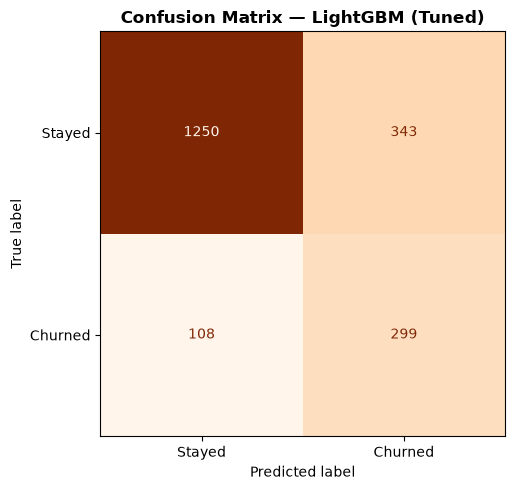

In [33]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Stayed", "Churned"])
disp.plot(ax=ax, colorbar=False, cmap="Oranges")
ax.set_title("Confusion Matrix — LightGBM (Tuned)", fontweight="bold")
plt.tight_layout()
plt.show()

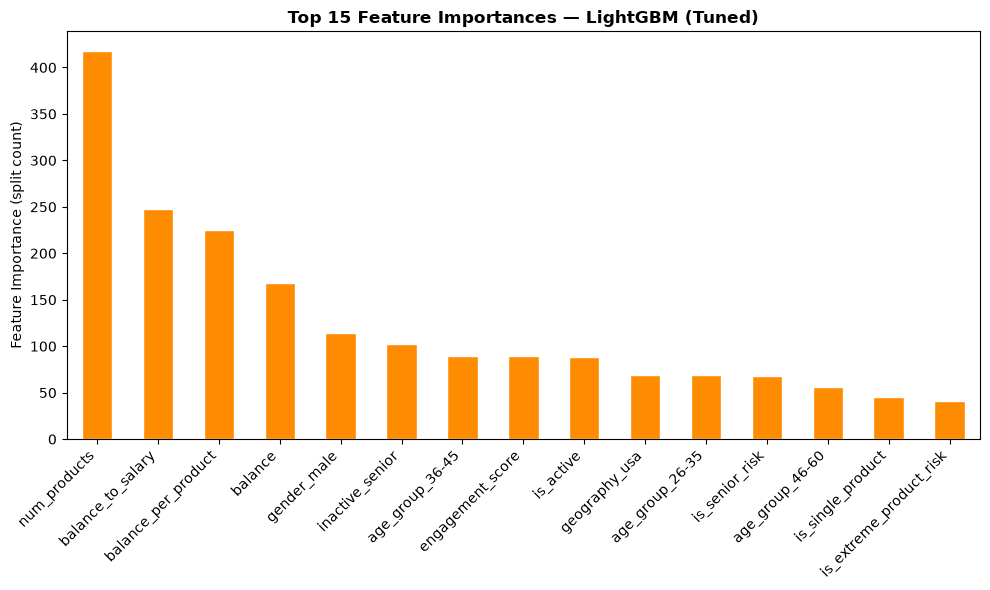

In [34]:
# Feature importances from best LightGBM (gain-based)
feat_imp = pd.Series(
    best_lgbm.feature_importances_,
    index=X_train_resampled.columns,
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.head(15).plot(kind="bar", ax=ax, color="darkorange", edgecolor="white")
ax.set_title("Top 15 Feature Importances — LightGBM (Tuned)", fontweight="bold")
ax.set_ylabel("Feature Importance (split count)")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Cross-Validation

In [35]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "roc_auc"  : "roc_auc",
    "recall"   : "recall",
    "precision": "precision",
    "f1"       : "f1",
    "accuracy" : "accuracy",
}

In [36]:
# Full end-to-end pipeline: preprocessor + KNN imputer + resampler + best LGBM
# This correctly prevents data leakage across each CV fold
cv_pipeline = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  KNNImputer(n_neighbors=10)),
    ("sampler",      RandomUnderSampler(random_state=42)),
    ("classifier",   best_lgbm),
])

cv_results = cross_validate(
    cv_pipeline,
    X_train,       # raw X_train — pipeline handles preprocessing inside each fold
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=1,
)

results_df = pd.DataFrame(cv_results)
results_df

,fit_time,score_time,test_roc_auc,test_recall,test_precision,test_f1,test_accuracy
0,2.847860,1.409543,0.837862,0.711656,0.485356,0.577114,0.787500
1,2.539060,1.358921,0.851241,0.766871,0.444840,0.563063,0.757500
2,2.501605,1.376032,0.838666,0.711656,0.448743,0.550415,0.763125
3,2.412441,1.473873,0.816953,0.677914,0.450102,0.541004,0.765625
4,2.349715,1.651673,0.841769,0.726994,0.471173,0.571773,0.778125


In [37]:
print("=== CV Summary (5-Fold Stratified) ===")
print(f"Mean CV ROC-AUC  : {results_df['test_roc_auc'].mean():.4f} +/- {results_df['test_roc_auc'].std():.4f}")
print(f"Mean CV Recall   : {results_df['test_recall'].mean():.4f} +/- {results_df['test_recall'].std():.4f}")
print(f"Mean CV Precision: {results_df['test_precision'].mean():.4f} +/- {results_df['test_precision'].std():.4f}")
print(f"Mean CV F1       : {results_df['test_f1'].mean():.4f} +/- {results_df['test_f1'].std():.4f}")
print(f"Mean CV Accuracy : {results_df['test_accuracy'].mean():.4f} +/- {results_df['test_accuracy'].std():.4f}")

=== CV Summary (5-Fold Stratified) ===
Mean CV ROC-AUC  : 0.8373 +/- 0.0126
Mean CV Recall   : 0.7190 +/- 0.0322
Mean CV Precision: 0.4600 +/- 0.0175
Mean CV F1       : 0.5607 +/- 0.0149
Mean CV Accuracy : 0.7704 +/- 0.0122


## Log Experiment to MLflow

In [38]:
try:
    with mlflow.start_run(run_name="LGBM HP Tuning — Final Evaluation"):
        mlflow.log_param("experiment_type",    "LGBM Hyperparameter Tuning")
        mlflow.log_param("imbalance_strategy", "RandomUnderSampler")
        mlflow.log_param("imputer",            "KNNImputer(n_neighbors=10)")
        mlflow.log_param("n_optuna_trials",    50)
        mlflow.log_param("dataset_rows",       X.shape[0])
        mlflow.log_param("dataset_features",   X.shape[1])
        mlflow.log_params(best_params)

        mlflow.log_metric("training_accuracy", accuracy_score(y_train, y_pred_train))
        mlflow.log_metric("training_recall",   recall_score(y_train, y_pred_train))
        mlflow.log_metric("training_roc_auc",  roc_auc_score(y_train, y_prob_train))
        mlflow.log_metric("test_accuracy",     accuracy_score(y_test, y_pred_test))
        mlflow.log_metric("test_recall",       recall_score(y_test, y_pred_test))
        mlflow.log_metric("test_precision",    precision_score(y_test, y_pred_test))
        mlflow.log_metric("test_f1",           f1_score(y_test, y_pred_test))
        mlflow.log_metric("test_roc_auc",      roc_auc_score(y_test, y_prob_test))
        mlflow.log_metric("cv_mean_recall",    results_df["test_recall"].mean())
        mlflow.log_metric("cv_mean_roc_auc",   results_df["test_roc_auc"].mean())
        mlflow.log_metric("cv_mean_f1",        results_df["test_f1"].mean())
        mlflow.log_metric("optuna_best_cv_roc_auc", study.best_value)

        for i, s in enumerate(results_df["test_roc_auc"]):
            mlflow.log_metric("cv_roc_auc_fold", s, step=i)
        for i, s in enumerate(results_df["test_recall"]):
            mlflow.log_metric("cv_recall_fold", s, step=i)

        # log model artifact with signature
        signature = mlflow.models.infer_signature(
            model_input=X_train_resampled.sample(20, random_state=42),
            model_output=best_lgbm.predict_proba(X_train_resampled.sample(20, random_state=42))[:, 1],
        )
        mlflow.sklearn.log_model(best_lgbm, artifact_path="lgbm_tuned_model", signature=signature)

    print("Experiment logged to MLflow.")
except Exception as e:
    print(f"[MLflow Notice] {e}")

2026/11/11 19:55:42 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run LGBM HP Tuning — Final Evaluation at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6/runs/9ba16289e7084a1cade6a5fab1fe9b4b
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/6
[MLflow Notice] The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['collections.OrderedDict', 'lightgbm.basic.Booster', 'lightgbm.sklearn.LGBMClassifier'].


## Final Summary

In [39]:
# Update RF HP Tuning values below after running 07_Churn_RF_HP_Tuning.ipynb
summary = pd.DataFrame({
    "Metric": [
        "Test ROC-AUC", "Test Recall", "Test Precision", "Test F1", "Test Accuracy",
        "CV ROC-AUC (mean)", "CV Recall (mean)", "CV F1 (mean)", "CV Accuracy (mean)",
    ],
    "Exp 4: XGB Spot-Check": [
        0.8473, 0.7224, 0.4696, 0.5692, 0.7775,
        0.8368, 0.7178, 0.5607, 0.7707,
    ],
    "Exp 5: XGB HP Tuning": [
        0.8492, 0.7518, 0.4525, 0.5736, 0.7725,
        0.8389, 0.7209, 0.5558, 0.7653,
    ],
    "Exp 6: RF HP Tuning": [
        None, None, None, None, None,   # fill in after running notebook 07
        None, None, None, None,
    ],
    "Exp 7: LGBM HP Tuning (This Notebook)": [
        round(roc_auc_score(y_test, y_prob_test),    4),
        round(recall_score(y_test, y_pred_test),     4),
        round(precision_score(y_test, y_pred_test),  4),
        round(f1_score(y_test, y_pred_test),         4),
        round(accuracy_score(y_test, y_pred_test),   4),
        round(results_df["test_roc_auc"].mean(),     4),
        round(results_df["test_recall"].mean(),      4),
        round(results_df["test_f1"].mean(),          4),
        round(results_df["test_accuracy"].mean(),    4),
    ],
})

summary

,Metric,Exp 4: XGB Spot-Check,Exp 5: XGB HP Tuning,Exp 6: RF HP Tuning,Exp 7: LGBM HP Tuning (This Notebook)
0,Test ROC-AUC,0.8473,0.8492,None,0.8460
1,Test Recall,0.7224,0.7518,None,0.7346
2,Test Precision,0.4696,0.4525,None,0.4657
3,Test F1,0.5692,0.5736,None,0.5701
4,Test Accuracy,0.7775,0.7725,None,0.7745
5,CV ROC-AUC (mean),0.8368,0.8389,None,0.8373
6,CV Recall (mean),0.7178,0.7209,None,0.7190
7,CV F1 (mean),0.5607,0.5558,None,0.5607
8,CV Accuracy (mean),0.7707,0.7653,None,0.7704
